# Model training and evaluation
The goal of this notebook is to determine what feature transformations are needed

## Import libraries

In [38]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, learning_curve
from xgboost import XGBClassifier

sys.path.append("..")
from src.data import split_data
from src.evaluate import best_f1_threshold, evaluate
from src.preprocessing import preprocessing, build_preprocessor

## Configuration

In [2]:
RANDOM_STATE = 42
N_SPLITS = 5
MAX_GAP = 0.03

## Load data

In [3]:
df = preprocessing()
X_train_preprocessed, X_val_preprocessed, X_test_preprocessed, y_train, y_val, y_test = split_data(df)

preprocessor = build_preprocessor(X_train_preprocessed)
X_train = preprocessor.fit_transform(X_train_preprocessed)

X_val = preprocessor.transform(X_val_preprocessed)
X_test = preprocessor.transform(X_test_preprocessed)

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

/home/isabel/Master_IA/XAI/xai-diabetes-readmission/.venv/lib/python3.13/site-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Raw data: 101,766 rows
After removing invalid encounters: 70,413 rows | positive rate 8.94%
Final: 70,413 rows x 36 columns


## Helper: train vs. CV score

`gap_pr_auc` = train PR-AUC minus CV PR-AUC. A large gap means the model is memorising the training data.

In [4]:
models = {}
results = []

def cv_evaluate(name, model, family=None, **params):
    s = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
        return_train_score=True,
    )
    models[name] = model
    row = {
        "model": name,
        "family": family,
        **params,
        "train_pr_auc": s["train_pr_auc"].mean(),
        "cv_pr_auc": s["test_pr_auc"].mean(),
        "gap_pr_auc": s["train_pr_auc"].mean() - s["test_pr_auc"].mean(),
        "train_roc_auc": s["train_roc_auc"].mean(),
        "cv_roc_auc": s["test_roc_auc"].mean()
    }
    results.append(row)
    return row

## Candidates

I will train the models with: `class_weight="balanced"` due to the data being very imbalanced.

### Logistic regression

In [5]:
lr_rows = []
for C in (0.001, 0.01, 0.1, 0.5, 1.0):
    row = cv_evaluate(
        f"LogReg C={C}",
        LogisticRegression(C=C, max_iter=2000, class_weight="balanced"),
        family="logreg"
    )
    lr_rows.append(row)
pd.DataFrame(lr_rows)[["model", "train_pr_auc", "cv_pr_auc", "gap_pr_auc", "cv_roc_auc"]]

,model,train_pr_auc,cv_pr_auc,gap_pr_auc,cv_roc_auc
0,LogReg C=0.001,0.159278,0.156001,0.003277,0.640960
1,LogReg C=0.01,0.171909,0.165013,0.006896,0.646997
2,LogReg C=0.1,0.177683,0.168477,0.009205,0.649058
3,LogReg C=0.5,0.179864,0.169364,0.010500,0.648081
4,LogReg C=1.0,0.180450,0.169240,0.011210,0.647608


### Random Forest

In [6]:
rf_rows = []
for leaf in (5, 20, 50, 100):
    print("RF leaf", leaf)
    model = RandomForestClassifier(
        n_estimators=500, max_depth=None, min_samples_leaf=leaf, max_features="sqrt",
        class_weight="balanced_subsample", random_state=RANDOM_STATE,
    )
    rf_rows.append(cv_evaluate(f"RF leaf={leaf}", model, family="rf", min_samples_leaf=leaf, max_depth=None))

RF leaf 5
RF leaf 20
RF leaf 50
RF leaf 100


In [7]:
for depth in (3, 5, 8):
    print("RF depth", depth)
    model = RandomForestClassifier(
        n_estimators=500, max_depth=depth, min_samples_leaf=50, max_features="sqrt",
        class_weight="balanced_subsample", random_state=RANDOM_STATE,
    )
    rf_rows.append(cv_evaluate(f"RF depth={depth}, leaf=50", model, family="rf", min_samples_leaf=50, max_depth=depth))

RF depth 3
RF depth 5
RF depth 8


In [8]:
pd.DataFrame(rf_rows)[["model", "train_pr_auc", "cv_pr_auc", "gap_pr_auc", "cv_roc_auc"]]

,model,train_pr_auc,cv_pr_auc,gap_pr_auc,cv_roc_auc
0,RF leaf=5,0.969235,0.176474,0.792761,0.654104
1,RF leaf=20,0.465020,0.172270,0.292749,0.654642
2,RF leaf=50,0.282357,0.166921,0.115437,0.651517
3,RF leaf=100,0.221412,0.162121,0.059292,0.647259
4,"RF depth=3, leaf=50",0.164680,0.156957,0.007724,0.640003
5,"RF depth=5, leaf=50",0.180762,0.161386,0.019376,0.643835
6,"RF depth=8, leaf=50",0.207255,0.164158,0.043097,0.647797


## XGBoost

In [9]:
xgb_configs = [
    {"max_depth": 2, "learning_rate": 0.05, "n_estimators": 500, "min_child_weight": 20, "reg_lambda": 10, "gamma": 1},
    {"max_depth": 3, "learning_rate": 0.05, "n_estimators": 500, "min_child_weight": 20, "reg_lambda": 10, "gamma": 1},
    {"max_depth": 3, "learning_rate": 0.03, "n_estimators": 500, "min_child_weight": 50, "reg_lambda": 20, "gamma": 2},
    {"max_depth": 4, "learning_rate": 0.03, "n_estimators": 500, "min_child_weight": 50, "reg_lambda": 20, "gamma": 2},
]

In [10]:
xgb_rows = []
for i, cfg in enumerate(xgb_configs, 1):
    print("XGB", i)
    model = XGBClassifier(
        objective="binary:logistic", eval_metric="aucpr", tree_method="hist",
        scale_pos_weight=scale_pos_weight, subsample=0.7, colsample_bytree=0.7,
        random_state=RANDOM_STATE, **cfg,
    )
    xgb_rows.append(cv_evaluate(f"XGB_{i}", model, family="xgb", **cfg))

XGB 1
XGB 2
XGB 3
XGB 4


In [11]:
pd.DataFrame(xgb_rows)[["model", "train_pr_auc", "cv_pr_auc", "gap_pr_auc", "cv_roc_auc"]]

,model,train_pr_auc,cv_pr_auc,gap_pr_auc,cv_roc_auc
0,XGB_1,0.196846,0.172441,0.024405,0.654575
1,XGB_2,0.230640,0.175763,0.054877,0.654761
2,XGB_3,0.207447,0.170266,0.037181,0.651201
3,XGB_4,0.236615,0.172465,0.064150,0.652383


## Train vs. CV curves

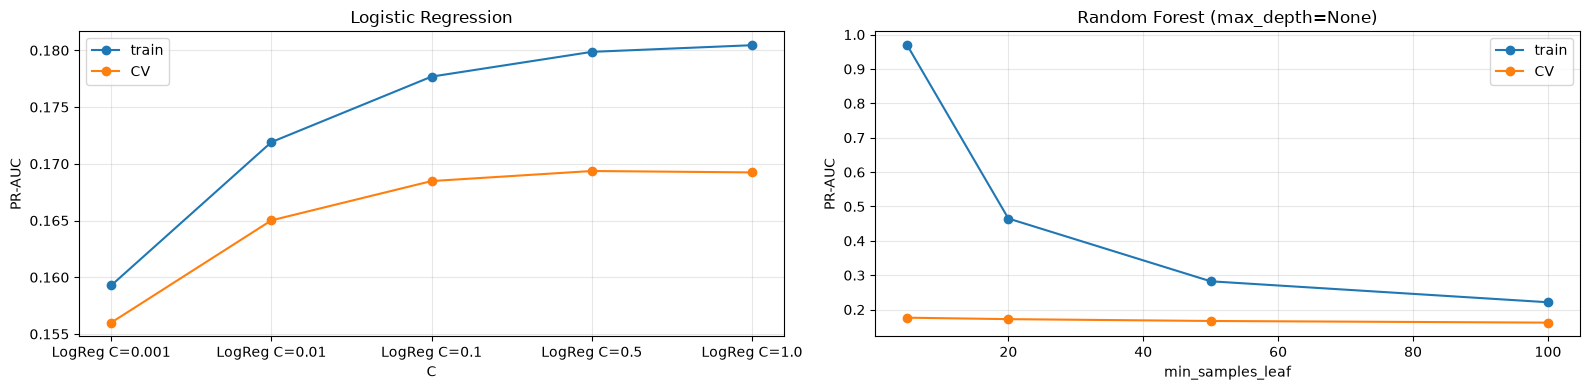

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

d = pd.DataFrame(lr_rows)
axes[0].plot(d["model"], d["train_pr_auc"], "o-", label="train")
axes[0].plot(d["model"], d["cv_pr_auc"], "o-", label="CV")
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("C")

d = pd.DataFrame([r for r in rf_rows if r["max_depth"] is None])
axes[1].plot(d["min_samples_leaf"], d["train_pr_auc"], "o-", label="train")
axes[1].plot(d["min_samples_leaf"], d["cv_pr_auc"], "o-", label="CV")
axes[1].set_title("Random Forest (max_depth=None)")
axes[1].set_xlabel("min_samples_leaf")

for ax in axes:
    ax.set_ylabel("PR-AUC"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Compare and select

In [ ]:
results_df = pd.DataFrame(results).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
results_df["no_overfit"] = results_df["gap_pr_auc"] <= MAX_GAP
results_df[results_df["no_overfit"]].round(4)

,model,family,train_pr_auc,cv_pr_auc,gap_pr_auc,train_roc_auc,cv_roc_auc,min_samples_leaf,max_depth,learning_rate,n_estimators,min_child_weight,reg_lambda,gamma,no_overfit
3,XGB_1,xgb,0.1968,0.1724,0.0244,0.6901,0.6546,NaN,2.0,0.05,500.0,20.0,10.0,1.0,True
6,LogReg C=0.5,logreg,0.1799,0.1694,0.0105,0.6710,0.6481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
7,LogReg C=1.0,logreg,0.1805,0.1692,0.0112,0.6713,0.6476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
8,LogReg C=0.1,logreg,0.1777,0.1685,0.0092,0.6697,0.6491,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
10,LogReg C=0.01,logreg,0.1719,0.1650,0.0069,0.6626,0.6470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
13,"RF depth=5, leaf=50",rf,0.1808,0.1614,0.0194,0.6661,0.6438,50.0,5.0,NaN,NaN,NaN,NaN,NaN,True
14,"RF depth=3, leaf=50",rf,0.1647,0.1570,0.0077,0.6514,0.6400,50.0,3.0,NaN,NaN,NaN,NaN,NaN,True
15,LogReg C=0.001,logreg,0.1593,0.1560,0.0033,0.6501,0.6410,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True


In [24]:
eligible = results_df[results_df["no_overfit"]]
if eligible.empty:
    raise ValueError("No model satisfies MAX_GAP. Add more regularisation or relax MAX_GAP.")

best_model = eligible.iloc[0]
best_lr = eligible.iloc[1]
print("Chosen model:", best_model["model"])
print("Chosen logistic regression:", best_lr["model"])
eligible.iloc[[0, 1]].round(4)

Chosen model: XGB_1
Chosen logistic regression: LogReg C=0.5


,model,family,train_pr_auc,cv_pr_auc,gap_pr_auc,train_roc_auc,cv_roc_auc,min_samples_leaf,max_depth,learning_rate,n_estimators,min_child_weight,reg_lambda,gamma,no_overfit
3,XGB_1,xgb,0.1968,0.1724,0.0244,0.6901,0.6546,NaN,2.0,0.05,500.0,20.0,10.0,1.0,True
6,LogReg C=0.5,logreg,0.1799,0.1694,0.0105,0.6710,0.6481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True


In [30]:
print("Selected model:", best_model["model"])
print(f"  train PR-AUC = {best_model['train_pr_auc']:.4f}")
print(f"  CV    PR-AUC = {best_model['cv_pr_auc']:.4f}")
print(f"  gap          = {best_model['gap_pr_auc']:.4f}")

print(f"  CV    ROC-AUC = {best_model['cv_roc_auc']:.4f}")

Selected model: XGB_1
  train PR-AUC = 0.1968
  CV    PR-AUC = 0.1724
  gap          = 0.0244
  CV    ROC-AUC = 0.6546


In [31]:
print("Selected model:", best_lr["model"])
print(f"  train PR-AUC = {best_lr['train_pr_auc']:.4f}")
print(f"  CV    PR-AUC = {best_lr['cv_pr_auc']:.4f}")
print(f"  gap          = {best_lr['gap_pr_auc']:.4f}")

print(f"  CV    ROC-AUC = {best_lr['cv_roc_auc']:.4f}")

Selected model: LogReg C=0.5
  train PR-AUC = 0.1799
  CV    PR-AUC = 0.1694
  gap          = 0.0105
  CV    ROC-AUC = 0.6481


In [ ]:
final_model = clone(models[best_model["model"]])
final_model_lr = clone(models[best_lr["model"]])

## Learning curve of the chosen model

If train and CV curves converge as data grows, the model is not overfitting. A persistent gap means more regularisation is needed.

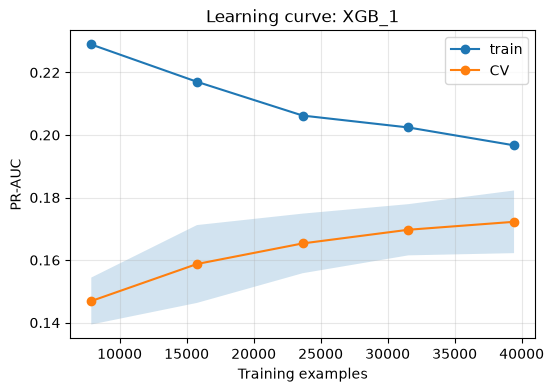

In [39]:
sizes, tr_scores, cv_scores = learning_curve(
    clone(final_model), X_train, y_train, cv=cv,
    scoring="average_precision", train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=1,
)

plt.figure(figsize=(6, 4))
plt.plot(sizes, tr_scores.mean(axis=1), "o-", label="train")
plt.plot(sizes, cv_scores.mean(axis=1), "o-", label="CV")
plt.fill_between(sizes, cv_scores.mean(1) - cv_scores.std(1), cv_scores.mean(1) + cv_scores.std(1), alpha=0.2)
plt.xlabel("Training examples"); plt.ylabel("PR-AUC"); plt.title(f"Learning curve: {chosen_name}")
plt.legend(); plt.grid(alpha=0.3); plt.show()

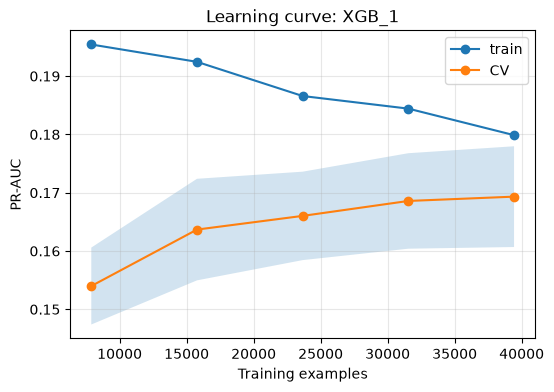

In [40]:
sizes, tr_scores, cv_scores = learning_curve(
    clone(final_model_lr), X_train, y_train, cv=cv,
    scoring="average_precision", train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=1,
)

plt.figure(figsize=(6, 4))
plt.plot(sizes, tr_scores.mean(axis=1), "o-", label="train")
plt.plot(sizes, cv_scores.mean(axis=1), "o-", label="CV")
plt.fill_between(sizes, cv_scores.mean(1) - cv_scores.std(1), cv_scores.mean(1) + cv_scores.std(1), alpha=0.2)
plt.xlabel("Training examples"); plt.ylabel("PR-AUC"); plt.title(f"Learning curve: {chosen_name}")
plt.legend(); plt.grid(alpha=0.3); plt.show()

The models are not overfitting because train and CV curves converge as data grows

## Threshold from out-of-fold predictions

The threshold is picked on out-of-fold train predictions, so validation and test data do not influence it.

In [ ]:
oof_prob = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
threshold = best_f1_threshold(y_train, oof_prob)
print(f"Threshold for {best_model["model"]}: {round(float(threshold), 4)}")

Threshold for XGB_1: 0.5716


In [ ]:
oof_prob_lr = cross_val_predict(final_model_lr, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
threshold_lr = best_f1_threshold(y_train, oof_prob_lr)
print(f"Threshold for {best_lr["model"]}: {round(float(threshold_lr), 4)}")

Threshold for LogReg C=0.5: 0.575


## Final check: train / validation / test

Fit on the full training set. Validation is a sanity check of the CV result; the test set is evaluated only here, once.

In [43]:
final_results = []

In [44]:
final_model.fit(X_train, y_train)

prob_train = final_model.predict_proba(X_train)[:, 1]
prob_val = final_model.predict_proba(X_val)[:, 1]
prob_test = final_model.predict_proba(X_test)[:, 1]

final_results.append(evaluate(best_model["model"], "train", y_train, prob_train, threshold))
final_results.append(evaluate(best_model["model"], "val", y_val, prob_val, threshold))
final_results.append(evaluate(best_model["model"], "test", y_test, prob_test, threshold))

In [45]:
final_model_lr.fit(X_train, y_train)

prob_train_lr = final_model_lr.predict_proba(X_train)[:, 1]
prob_val_lr = final_model_lr.predict_proba(X_val)[:, 1]
prob_test_lr = final_model_lr.predict_proba(X_test)[:, 1]

final_results.append(evaluate(best_lr["model"], "train", y_train, prob_train_lr, threshold_lr))
final_results.append(evaluate(best_lr["model"], "val", y_val, prob_val_lr, threshold_lr))
final_results.append(evaluate(best_lr["model"], "test", y_test, prob_test_lr, threshold_lr))

In [46]:
pd.DataFrame(final_results)

,model,split,roc_auc,pr_auc,brier,f1,precision,recall,threshold
0,XGB_1,train,0.684134,0.193431,0.222619,0.256342,0.190618,0.391235,0.571642
1,XGB_1,val,0.651138,0.165184,0.225193,0.234672,0.175818,0.352754,0.571642
2,XGB_1,test,0.667812,0.180577,0.222123,0.247350,0.185578,0.370763,0.571642
3,LogReg C=0.5,train,0.668791,0.178782,0.225772,0.241155,0.176794,0.379201,0.575035
4,LogReg C=0.5,val,0.641915,0.157074,0.228590,0.223733,0.164747,0.348517,0.575035
5,LogReg C=0.5,test,0.658970,0.170673,0.225095,0.236135,0.173935,0.367585,0.575035
